In [52]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

In [53]:
path = "../data/processed"

df_test = pd.read_csv(f"{path}/test.csv")
df_train = pd.read_csv(f"{path}/train.csv")
df_val = pd.read_csv(f"{path}/val.csv")

In [54]:
df_train.head()

,text,label,cleaned_text
0,“Worry is a down payment on a problem you may never have'. Joyce Meyer. #motivation #leadership #worry,2,worry down payment problem may never joyce meyer motivation leadership worry
1,My roommate: it's okay that we can't spell because we have autocorrect. #terrible #firstworldprobs,0,roommate okay cannot spell autocorrect terrible firstworldprobs
2,No but that's so cute. Atsu was probably shy about photos before but cherry helped her out uwu,1,no cute atsu probably shy photo cherry help uwu
3,"Rooneys fucking untouchable isn't he? Been fucking dreadful again, depay has looked decent(ish)tonight",0,rooneys fuck untouchable not fuck dreadful depay look decent ish tonight
4,it's pretty depressing when u hit pan on ur favourite highlighter,3,pretty depress hit pan favourite highlighter


In [55]:
print((df_train["cleaned_text"].str.len() == 0).sum(), "empty rows")
print((df_val["cleaned_text"].str.len() == 0).sum(), "empty rows")
print((df_test["cleaned_text"].str.len() == 0).sum(), "empty rows")

0 empty rows
0 empty rows
0 empty rows


In [56]:
y_train = df_train["label"].values
y_test = df_test["label"].values
y_val = df_val["label"].values

In [57]:
df_train.isna().sum()

text            0
label           0
cleaned_text    0
dtype: int64

In [58]:
df_val.isna().sum()

text            0
label           0
cleaned_text    0
dtype: int64

In [59]:
df_test.isna().sum()

text            0
label           0
cleaned_text    0
dtype: int64

In [60]:
def scores(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average='macro')
    }


def make_clf():
    """One classifier configuration shared by every experiment, so results are comparable."""
    return LogisticRegression(C=1.0, max_iter=2000, class_weight='balanced', random_state=42)

In [61]:
tfidf = TfidfVectorizer(min_df=2, ngram_range=(1, 2), max_features=2000, norm="l2")
X_train = tfidf.fit_transform(df_train['cleaned_text'])
X_val = tfidf.transform(df_val['cleaned_text'])

model = make_clf()
model.fit(X_train, y_train)
y_pred = model.predict(X_val)

print("Baseline on validation:", scores(y_val, y_pred))

Baseline on validation: {'accuracy': 0.6657754010695187, 'macro_f1': 0.6066486990152554}


In [62]:
results_mindf = []
for min_df in [1, 2, 5, 10, 20]:
    vectorizer = TfidfVectorizer(min_df=min_df, ngram_range=(1, 2), max_features=2000, norm="l2")
    X_tr = vectorizer.fit_transform(df_train['cleaned_text'])
    X_va = vectorizer.transform(df_val['cleaned_text'])

    model = make_clf()
    model.fit(X_tr, y_train)
    preds = model.predict(X_va)
    results_mindf.append({
        "min_df": min_df,
        "vocabulary": len(vectorizer.vocabulary_),
        **scores(y_val, preds)
    })

results_mindf = pd.DataFrame(results_mindf)
results_mindf

,min_df,vocabulary,accuracy,macro_f1
0,1,2000,0.663102,0.602255
1,2,2000,0.665775,0.606649
2,5,1239,0.649733,0.585359
3,10,576,0.620321,0.561101
4,20,266,0.590909,0.538141


In [63]:
results_maxf = []
for max_features in [500, 1000, 2000, 5000, 7000]:
    vectorizer = TfidfVectorizer(min_df=2, ngram_range=(1, 2), max_features=max_features, norm="l2")
    X_tr = vectorizer.fit_transform(df_train["cleaned_text"])
    X_va = vectorizer.transform(df_val["cleaned_text"])

    model = make_clf()
    model.fit(X_tr, y_train)
    preds = model.predict(X_va)

    results_maxf.append({"max_features": max_features,
                         "vocabulary": len(vectorizer.vocabulary_),
                         **scores(y_val, preds)})

results_maxf = pd.DataFrame(results_maxf)
results_maxf

,max_features,vocabulary,accuracy,macro_f1
0,500,500,0.622995,0.562524
1,1000,1000,0.644385,0.582553
2,2000,2000,0.665775,0.606649
3,5000,5000,0.663102,0.599498
4,7000,6025,0.668449,0.604482


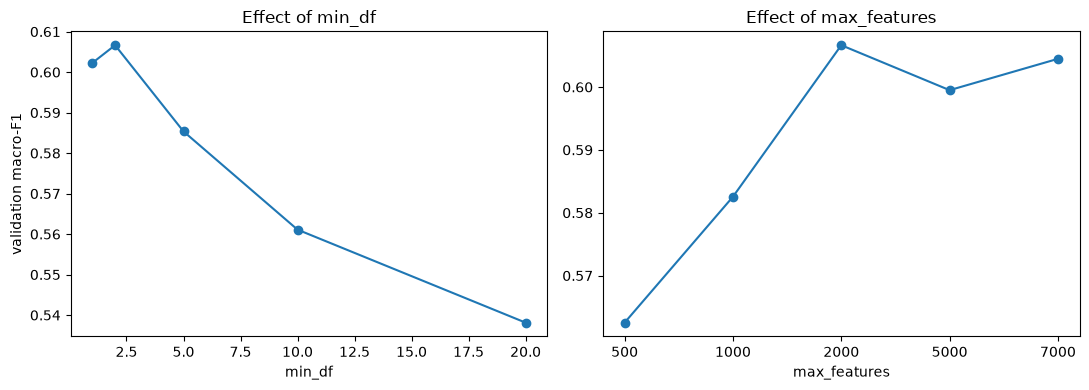

In [64]:
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(results_mindf["min_df"], results_mindf["macro_f1"], marker="o")
plt.xlabel("min_df")
plt.ylabel("validation macro-F1")
plt.title("Effect of min_df")

plt.subplot(1, 2, 2)
plt.plot(results_maxf["max_features"].astype(str), results_maxf["macro_f1"], marker="o")
plt.xlabel("max_features")
plt.title("Effect of max_features")

plt.tight_layout()
plt.show()

In [ ]:
best_min_df = int(results_mindf.loc[results_mindf["macro_f1"].idxmax(), "min_df"])
best_max_features = int(results_maxf.loc[results_maxf["macro_f1"].idxmax(), "max_features"])
print("best min_df:", best_min_df, "| best max_features:", best_max_features)

tfidf = TfidfVectorizer(min_df=best_min_df, ngram_range=(1, 2), max_features=best_max_features, norm='l2')
X_train = tfidf.fit_transform(df_train['cleaned_text'])
X_val = tfidf.transform(df_val['cleaned_text'])
X_test = tfidf.transform(df_test['cleaned_text'])

clf_tfidf = make_clf()
clf_tfidf.fit(X_train, y_train)

print("Chosen setting on validation:", scores(y_val, clf_tfidf.predict(X_val)))

pred_tfidf = clf_tfidf.predict(X_test)

best min_df: 2 | best max_features: 2000
Chosen setting on validation: {'accuracy': 0.6657754010695187, 'macro_f1': 0.6066486990152554}


In [66]:
def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    print(f"{name:12s} accuracy = {acc:.3f} | macro-F1 = {f1:.3f}")
    return acc, f1

acc_tfidf, f1_tfidf = evaluate("TF-IDF", y_test, pred_tfidf)

TF-IDF       accuracy = 0.690 | macro-F1 = 0.649


              precision    recall  f1-score   support

       anger       0.77      0.72      0.75       558
         joy       0.69      0.73      0.71       358
    optimism       0.38      0.56      0.46       123
     sadness       0.72      0.64      0.68       382

    accuracy                           0.69      1421
   macro avg       0.64      0.66      0.65      1421
weighted avg       0.70      0.69      0.69      1421



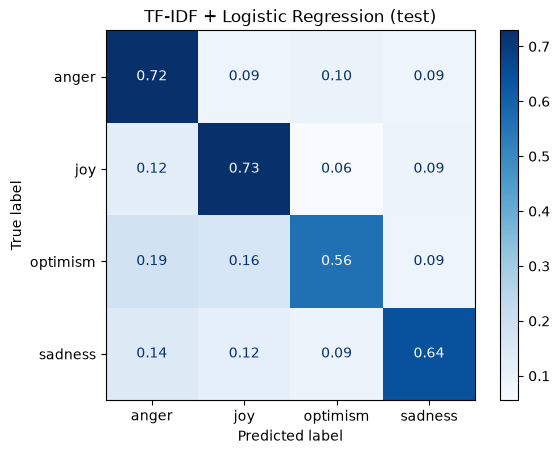

In [67]:
names = ["anger", "joy", "optimism", "sadness"]
print(classification_report(y_test, pred_tfidf, target_names=names))

ConfusionMatrixDisplay.from_predictions(y_test, pred_tfidf, display_labels=names,
                                        normalize="true", values_format=".2f", cmap="Blues")
plt.title("TF-IDF + Logistic Regression (test)")
plt.show()

In [68]:
errors = df_test.assign(true=[names[i] for i in y_test],
                          pred=[names[i] for i in pred_tfidf])
errors = errors[errors["true"] != errors["pred"]]
pd.set_option("display.max_colwidth", 120)
errors[["text", "true", "pred"]].sample(10, random_state=42)

,text,true,pred
249,"@user @user oh, that too! 🤣",joy,sadness
1417,@user I've finished reading it; simply mind-blogging. The writer said 'to be continued' but I haven't found part 2. ...,sadness,optimism
499,Who also miss glee ? #gleek #glee #GleeForever #DreamsComeTrue #dontstopbelieving #gleecast @user,sadness,joy
926,"Not all people are #concern, some are just enjoying seeing people in #miserable.",sadness,anger
1283,@user @user the one college stadium I really hope the offense is atrocious Who TF is Derron Smith?,anger,joy
1287,Getting out of the car park could take longer than the Jimmy Carr show ran #nightmare,anger,sadness
792,Hey @user #imwearingyourshirt today!! #humbleandkind #awesomeness #timmcgraw #wqmx @user @user @user,joy,sadness
384,"yikes got my first job interview next week, haven't had one in years",joy,sadness
1317,Your smile could never make me frown.,joy,optimism
1290,"Quick annoyingly vague scream into the void: AAAAAAAAAAGH. I'm nervous, excited, terrified, trying not to get my hop...",anger,optimism
